## Baixando as Bibliotecas Necessarias

In [ ]:
import kagglehub
import shutil
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, f1_score, recall_score, classification_report
import seaborn as sns
from google.colab import files
import shap


## 1.  Baixando Dados do Dataset (  [https://www.kaggle.com/datasets/anujms/car-damage-detection/data?select=data1a](https://www.kaggle.com/datasets/anujms/car-damage-detection/data?select=data1a) )




In [ ]:
DATASET_PATH = kagglehub.dataset_download("anujms/car-damage-detection")

print("Path to dataset files:", DATASET_PATH)

Using Colab cache for faster access to the 'car-damage-detection' dataset.
Path to dataset files: /kaggle/input/car-damage-detection


In [ ]:
def verificar_disposicao(diretorio_base):
    # Aponta para a pasta de treinamento dentro de data1a
    caminho_treino = os.path.join(diretorio_base, "data1a", "training")

    print(f"Verificando pastas em: {caminho_treino}")

    # Mapeamento para nomes amigáveis em português
    nomes_classes = {
        "00-damage": "Carro com defeito",
        "01-whole": "Carro intacto"
    }

    if os.path.exists(caminho_treino):
        for pasta in sorted(os.listdir(caminho_treino)):
            caminho_completo = os.path.join(caminho_treino, pasta)
            if os.path.isdir(caminho_completo):
                total_arquivos = len(os.listdir(caminho_completo))
                nome_formatado = nomes_classes.get(pasta, pasta)
                print(f"Classe: {nome_formatado} | Total de imagens: {total_arquivos}")
    else:
        print("Pasta de treinamento não encontrada no caminho especificado.")

verificar_disposicao(DATASET_PATH)

Verificando pastas em: /kaggle/input/car-damage-detection/data1a/training
Classe: Carro com defeito | Total de imagens: 920
Classe: Carro intacto | Total de imagens: 920


# 2. Pré Processamento de Dados

In [ ]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# Caminhos das pastas de treino e validação
train_dir = os.path.join(DATASET_PATH, 'data1a', 'training')
validation_dir = os.path.join(DATASET_PATH, 'data1a', 'validation')

print("Conjunto de Treino (training):")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True
)

print("\nConjunto de Validação (validation):")
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

class_names = train_dataset.class_names
print(f"\nClasses identificadas: {class_names}")

Conjunto de Treino (training):
Found 1840 files belonging to 2 classes.

Conjunto de Validação (validation):
Found 460 files belonging to 2 classes.

Classes identificadas: ['00-damage', '01-whole']


## Função de Normalização

In [ ]:
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_dataset = train_dataset.map(normalize)
validation_dataset = validation_dataset.map(normalize)

print("Normalizados com sucesso!")

Normalizados com sucesso!


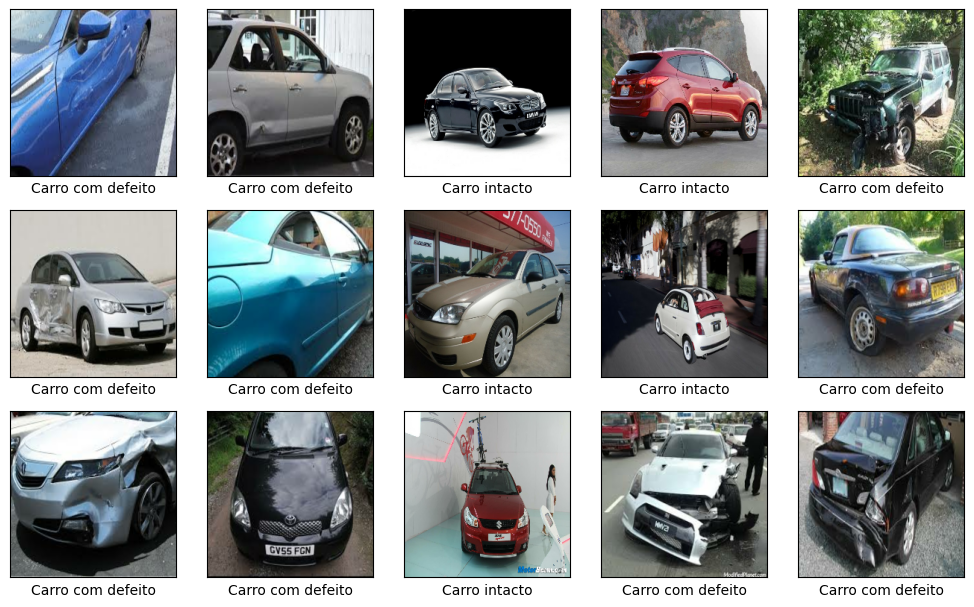

In [ ]:
class_names = ['Carro com defeito', 'Carro intacto']

# Como o dataset está em batches, pegamos apenas o primeiro batch de dados
for images_batch, labels_batch in train_dataset.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(min(15, len(images_batch))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(images_batch[i].numpy())
        label_idx = int(labels_batch[i].numpy()[0])
        plt.xlabel(class_names[label_idx])
    plt.tight_layout()


## 3. Construir a Arquitetura da CNN

In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), padding='same', activation='relu', strides=(1,1), input_shape=(IMG_HEIGHT,IMG_WIDTH,3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), padding='same', activation='relu', strides=(1,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), padding='same', activation='relu', strides=(1,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), padding='same', activation='relu', strides=(1,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(256, (3,3), padding='same', activation='relu', strides=(1,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')

])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 56, 56, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 14, 14, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │     3,211,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,639,297 (13.88 MB)

 Trainable params: 3,638,209 (13.88 MB)

 Non-trainable params: 1,088 (4.25 KB)

## 4. Compilar o Modelo

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

## 5. Treinar o Modelo

In [ ]:
# Configurando o Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=200,
    callbacks=[early_stopping]
)

Epoch 1/200


/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/nn.py:1286: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Sigmoid activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


58/58 ━━━━━━━━━━━━━━━━━━━━ 28s 276ms/step - accuracy: 0.7120 - loss: 1.2344 - val_accuracy: 0.5000 - val_loss: 1.4662
Epoch 2/200
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.7766 - loss: 0.5051 - val_accuracy: 0.5000 - val_loss: 1.2255
Epoch 3/200
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.8120 - loss: 0.4204 - val_accuracy: 0.5000 - val_loss: 1.2086
Epoch 4/200
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.8418 - loss: 0.3585 - val_accuracy: 0.5000 - val_loss: 3.3391
Epoch 5/200
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.8641 - loss: 0.3330 - val_accuracy: 0.6196 - val_loss: 0.6627
Epoch 6/200
58/58 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.8793 - loss: 0.2921 - val_accuracy: 0.5891 - val_loss: 0.9392
Epoch 7/200
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.8864 - loss: 0.2741 - val_accuracy: 0.5696 - val_loss: 1.2789
Epoch 8/200
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.8962 - loss: 0.2390 - val_accuracy: 0.6413 - val

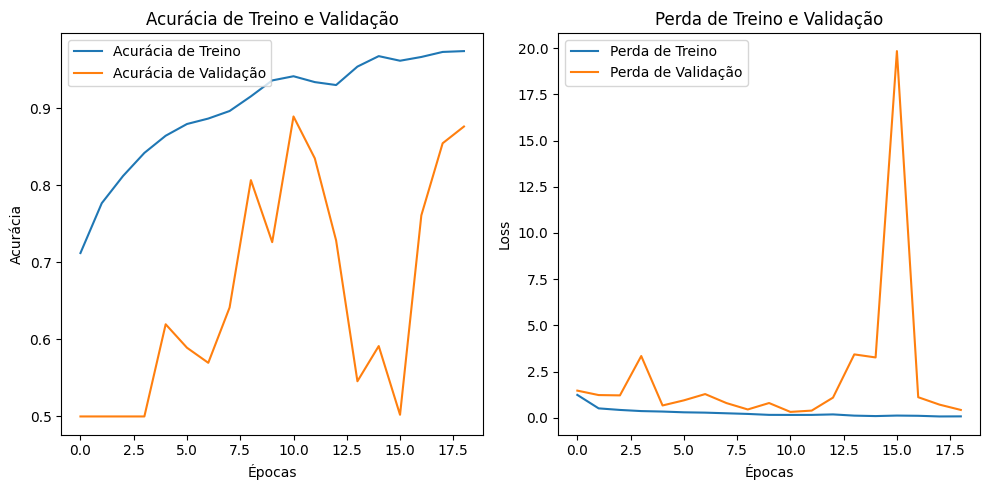

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Acurácia de Treino')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.title('Acurácia de Treino e Validação')
plt.legend()
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.savefig('Acurácia_Treino_Validação.png', bbox_inches='tight', dpi=300)

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Perda de Treino')
plt.plot(history.history['val_loss'], label='Perda de Validação')
plt.title('Perda de Treino e Validação')
plt.legend()
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.savefig('Perda_Treino_Validação.png', bbox_inches='tight', dpi=300)
plt.legend()

plt.tight_layout()

## Salvando o Modelo

In [ ]:
model.save('model.keras')

In [ ]:
model_carregado = tf.keras.models.load_model('model.keras')

## 6. Avaliação do modelo

In [ ]:
y_pred_prob = model.predict(validation_dataset)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = np.concatenate([y.numpy() for x, y in validation_dataset], axis=0).flatten()

relatorio = classification_report(y_true, y_pred, target_names=class_names)

print("Relatório de Classificação:\n")
print(relatorio)

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step
Relatório de Classificação:

                   precision    recall  f1-score   support

Carro com defeito       0.88      0.90      0.89       230
    Carro intacto       0.90      0.87      0.89       230

         accuracy                           0.89       460
        macro avg       0.89      0.89      0.89       460
     weighted avg       0.89      0.89      0.89       460



## 7.  Matriz de Confusão

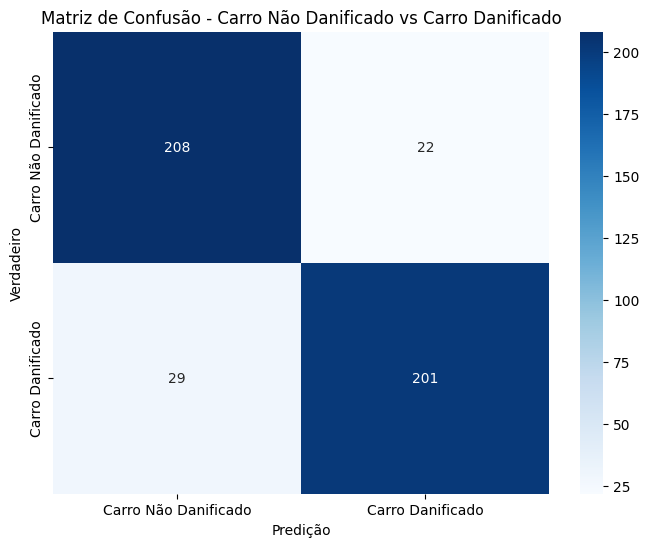

In [ ]:
if "y_true" not in globals() or "y_pred" not in globals():
    y_pred_probs = []
    y_true = []

    for images, labels in train_dataset:
        predictions = model.predict(images, verbose=0)
        y_pred_probs.extend(predictions)
        y_true.extend(labels.numpy())

    # converte probabilidades em classes (0 ou 1)
    y_pred = [1 if p > 0.5 else 0 for p in y_pred_probs]

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Carro Não Danificado', 'Carro Danificado'], yticklabels=['Carro Não Danificado', 'Carro Danificado'])
plt.xlabel('Predição')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão - Carro Não Danificado vs Carro Danificado')
plt.savefig('confusion_matrix.png', bbox_inches='tight', dpi=300)
plt.show()

## 8. IA Explicavel

In [ ]:
# Extraindo um lote de imagens do dataset para servir de referência (background) e teste
for images, labels in train_dataset.take(1):
    background = images[:100].numpy()
    test_sample = images[:5].numpy()
    real_classes = labels[:5].numpy().astype(int).flatten()

pred = model.predict(test_sample)
pred_classes = (pred >= 0.5).astype(int).flatten()

print("Classes Preditas:", pred_classes)
print("Classes Reais:   ", real_classes)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Classes Preditas: [0 0 1 0 1]
Classes Reais:    [0 0 1 0 1]


In [ ]:
explainer = shap.DeepExplainer(model, background)

shap_values = explainer.shap_values(test_sample)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1137
Received: inputs=['Tensor(shape=(32, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1137
Received: inputs=['Tensor(shape=(64, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1137
Received: inputs=['Tensor(shape=


Classe prevista: Carro com defeito | Classe real: Carro com defeito


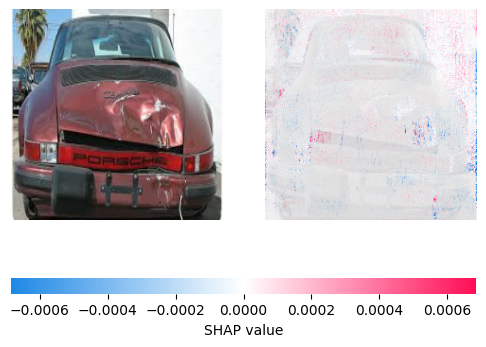


Classe prevista: Carro com defeito | Classe real: Carro com defeito


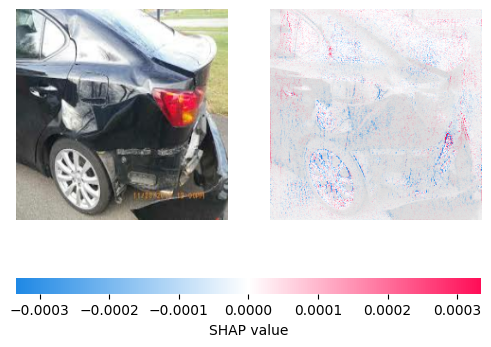


Classe prevista: Carro intacto | Classe real: Carro intacto


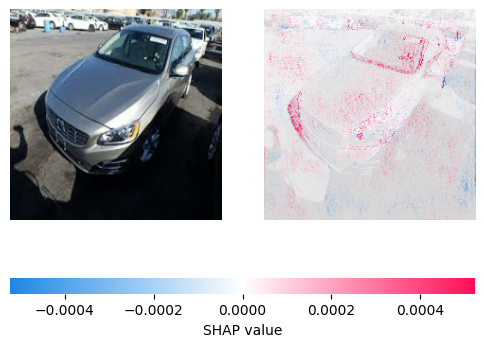


Classe prevista: Carro com defeito | Classe real: Carro com defeito


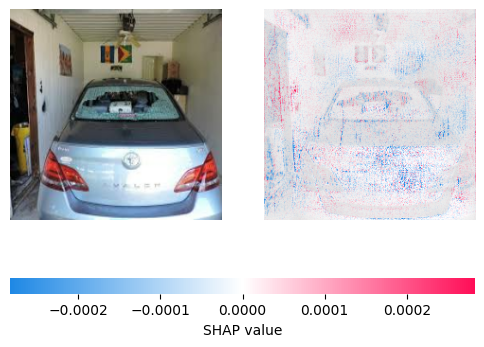


Classe prevista: Carro intacto | Classe real: Carro intacto


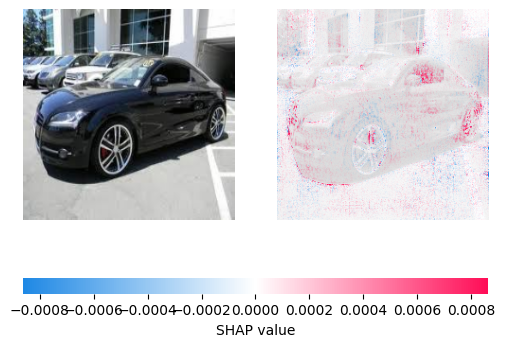

In [ ]:
for i in range(len(test_sample)):
    print(f"\nClasse prevista: {class_names[pred_classes[i]]} | Classe real: {class_names[real_classes[i]]}")

    current_shap = shap_values[i, :, :, :, 0]
    current_img = test_sample[i, :, :, :]

    shap.image_plot(current_shap, current_img)